# Rare vs typical events, split by a σ threshold on the acceleration

Copy of the essential steps of `turb_interpretation_rare_typical_final.ipynb` (turbulence_final runs, same seeds, same Theta_reg loading). The only change is **how a signal is called rare**.

**Old criterion.** Rank the signals by their peak acceleration and call the top 1% (or 5%) rare. This always gives the same number of rare signals, however mild the tail is.

**New criterion (suggested by a turbulence researcher).** Look at the PDF of the acceleration first. Then call a signal rare if its acceleration reaches **20–30 standard deviations** somewhere, so that the rare set probes the far tails of the PDF:

- $a(t) = x(t+1) - x(t)$, the lag-1 increment of the signal (the code's "acceleration", same as before);
- $\sigma_a$ = std of $a$ over **every point of every signal of `x1`**. This single number is used for the data **and** for the model samples, so the threshold is the same physical level for both;
- a signal is **rare** if $e = \max_t |a(t)|/\sigma_a \ge$ `SIGMA_RARE`.

**How few rare signals there are** (measured on the local data file on 2026-10-16, same preprocessing as here):

| threshold | rare in `x1` (n = 10000) | rare in all data (n = 30000), σ_a of `x1` |
|---|---|---|
| 15σ | 102 | 289 |
| 20σ | 33 | 96 |
| 25σ | 11 | 33 |
| 30σ | 4 | 10 |

With so few rare signals, two things change compared to the old notebook:
- `SPLIT_ON = 'all'` (Knobs) also uses the 20000 held-out signals that the model never saw, normalized with `x1`'s mean and std (the same transform as `x1`). θ is still the one fitted on `x1`; we only *evaluate* log p on more signals.
- Dropped: λ-selection cells, MGD-vs-REG variance, d_eff, compensation and residual-variance sections (a regression with hundreds of features on a few dozen rare signals means nothing), sign checks.

**Contents.** Knobs · load runs, θ, potentials · model samples · **acceleration PDF, data vs model** · σ split + examples · per-family log p contribution by category · log p rare vs typical · Florentin's plot · 1. per-family gap D · 2. robustness to the threshold · 3. continuous version · 4. model samples: log p and rare events

**How to use.** Settings are in the **Knobs** cell. After changing `SIGMA_RARE`, re-run from the *σ split* cell down. After changing `SPLIT_ON`, re-run from the config cell.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
import sys, os, re, math
from types import SimpleNamespace
import json

root = Path().resolve()
sys.path.insert(0, str(root / '../codes'))
from sde_routines import *
from utils import *
from utils_experiment import *
from filters_bank import *
from potentials import *
from ortho_wavelet import *
from check_potentials import *  # theta_column_map, decode_mod2_stq, etc.

sys.path.insert(0, str(root / '../data'))
from data_loader import *

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device, '|', root)

pd.set_option('display.float_format', lambda x: f'{x:.3g}')

%matplotlib inline

device: cuda | /lustre/fswork/projects/rech/wbg/ukv59en/MGD-for-Maximum-Entropy-Generation/turbulence


## Knobs

In [2]:
# --- rare/typical split: sigma threshold on the acceleration ---
# a(t) = x(t+1) - x(t); SIGMA_A = std of a over every point of x1 (one number, used for data and model).
# A signal is 'rare' if max_t |a(t)| >= SIGMA_RARE * SIGMA_A.
SIGMA_RARE = 20
SIGMA_THRESHOLDS = [10, 15, 20, 25, 30]   # section 2 (robustness) and the PDF/tail plots; SIGMA_RARE added automatically

# Which signals to split and evaluate log p on:
#   'x1'  : the n1 = 10000 training signals (20 sigma -> 33 rare)
#   'all' : x1 + the held-out signals, normalized with x1's mean/std (20 sigma -> 96 rare)
SPLIT_ON = 'all'

# --- examples of typical / rare signals ---
N_EVENT_EXAMPLES = 8             # signals shown per category
EVENT_PICK = 'random'            # 'random' or 'extreme' (rare = most extreme, typical = least extreme)
EVENT_SEED = 0

# --- zoom panel in the per-family energy cell ---
ZOOM_FAMILIES = ['Scattering_Fourth_Order_Mod2_Real_Q1', 'Scattering_Fourth_Order_Mod2_Imag_Q1', 'TOTAL']

# --- bootstraps over the rare signals ---
N_BOOT = 1000
BOOT_SEED = 0

In [3]:
import os

# LOCAL vs JEAN ZAY -- load_turbulence_1d()'s default path in data_loader.py
# is Jean-Zay-only (/lustre/...). Flip to "jean_zay" there instead of editing this.
# PHI_CHUNK_SIZE batches phi(x)/grad(x) evaluation over the sample dim -- evaluating
# Scattering_Fourth_Order_Mod2_{Real,Imag}_Q1 on the full n1=5000 batch at once
# materializes a ~5.9GB intermediate BEFORE any reduction (measured directly:
# DefaultCPUAllocator asked for exactly 5898240000 bytes) -- chunking avoids it
# with no change to the result. Jean Zay has enough RAM/GPU memory to skip it.
RUN_LOCATION = "jean_zay"   # "local" or "jean_zay"

if RUN_LOCATION == "local" and torch.cuda.is_available():
    # A fixed chunk_size=500 assumes a GPU mostly to ourselves. On a GPU shared with
    # other processes (measured here: a co-tenant job holding ~19.5/22GB, leaving as
    # little as ~40MB free) that assumption breaks and 500 alone can still OOM. The
    # ~5.9GB/5000-sample intermediate above scales to ~1.2MiB/sample, so size the
    # chunk from what's ACTUALLY free right now (measured before potentials/data are
    # loaded, so this slightly overestimates later headroom -- the 2x margin covers
    # that plus the other job's usage not being static).
    free_bytes, _ = torch.cuda.mem_get_info()
    BYTES_PER_SAMPLE = 1.2 * 1024 ** 2
    PHI_CHUNK_SIZE = max(1, int(free_bytes / BYTES_PER_SAMPLE / 2))
    print(f"GPU free memory: {free_bytes / 1e6:.0f}MB -> PHI_CHUNK_SIZE = {PHI_CHUNK_SIZE}")
else:
    PHI_CHUNK_SIZE = 500 if RUN_LOCATION == "local" else None

if RUN_LOCATION == "local":
    local_turbulence_path = (root / "../data/data_files/turbulence_1d_period.pt").resolve()
    if local_turbulence_path.exists():
        os.environ["TURBULENCE_1D_DATA_PATH"] = str(local_turbulence_path)
    else:
        print(f"WARNING: {local_turbulence_path} not found -- load_turbulence_1d() "
              f"will fall back to its Jean Zay default path and fail locally.")
print(f"RUN_LOCATION = {RUN_LOCATION!r}, PHI_CHUNK_SIZE = {PHI_CHUNK_SIZE!r}")

RUN_LOCATION = 'jean_zay', PHI_CHUNK_SIZE = None


## Load the runs, the data, θ and the fitted potentials

Same seeds, λ and L_6<0-constrained Theta_reg as `turb_interpretation_rare_typical_final.ipynb`. On top of `x1`, the cell builds `x_all` (every preprocessed signal, normalized with `x1`'s mean and std) and `x_eval`, the set the split and log p are computed on (`SPLIT_ON`).

In [4]:
# --- Latest turbulence runs: 'turbulence_final' arm, 5 seeds with the lam sweep done 2026-10-14 ---
# Seeds 900, 901, 903, 904, 905 (902 didn't finish in time, 905 was its replacement — memory
# [[turbulence-final-lamselect-1014]]). Seed 900 has an earlier test-launch timestamp.
ARM = 'turbulence_final'
GROUP = ('turbulencesynth_M256_J8_Q3_sigma3.5_nt55000_n1_10000_lam0.0'
         '_thomas_nsub1_moment_f64_dedupfilt1e-08_terms54d17f3b_turbulence_final')
RUN = ('turbulencesynth_M256_J8_Q3_sigma3.5_nt55000_n1_10000_lam0.0'
       '_thomas_nsub1_moment_f64_dedupfilt1e-08'
       '_seed_{seed}_terms54d17f3b_turbulence_final_{ts}')

TS_BY_SEED = {900: '20261013_1355',          # earlier test launch
              901: '20261013_1542', 903: '20261013_1542',
              904: '20261013_1542', 905: '20261013_1542'}
CONFIGS = [RUN.format(seed=s, ts=TS_BY_SEED[s]) for s in sorted(TS_BY_SEED)]  # 5 configs

LAM = 0.0005            # offline Theta_reg solves exist for several λ; pick after the cross-seed cell
RIDGE = 1e-4          # confirmed from any seed's config.json: 'regularization': 0.0001
LAM_LABEL = 'theta_t (no Theta_reg)' if LAM is None else f'lam={LAM:g}'

# Point at the sweep that actually ran (resolve_lamsweep.sh output, project space, NOT $SCRATCH):
sweep_root = root / 'saved_results' / 'theta_reg_lamsweep'   # per-config subdirs below

exp_dir_by_seed, cfg_by_seed, config_by_seed, theta_path_by_seed = {}, {}, {}, {}
for config in CONFIGS:
    exp_dir = root / 'experiments' / GROUP / config
    assert exp_dir.is_dir(), f'missing {exp_dir}'
    cfg = json.loads((exp_dir / 'config.json').read_text())
    key = f"seed{cfg['seed']}"
    exp_dir_by_seed[key], cfg_by_seed[key], config_by_seed[key] = exp_dir, cfg, config
    solved = sorted((sweep_root / config).glob('lam*_ridge*.pt'))
    print(f"{key}: offline Theta_reg solves: {[p.stem for p in solved] or 'none'}")
    theta_path_by_seed[key] = sweep_root / config / f'lam{LAM:g}_ridge{RIDGE:g}_moment_mask.pt' if LAM is not None else None

missing = [str(p) for p in theta_path_by_seed.values() if p is None or not p.exists()]
HAVE_REG = LAM is not None and not missing
print(f"HAVE_REG = {HAVE_REG}" + ('' if HAVE_REG else f"  (LAM={LAM}; missing: {missing})"))

seed_keys = sorted(cfg_by_seed, key=lambda s: int(s.replace('seed', '')))
cfg = cfg_by_seed[seed_keys[0]]
skip = {'timestamp', 'config_name', 'seed'}
for k in seed_keys[1:]:
    diff = {q for q in set(cfg) | set(cfg_by_seed[k]) if q not in skip and cfg.get(q) != cfg_by_seed[k].get(q)}
    assert not diff, f'{k} differs from {seed_keys[0]} in {diff}'
print(f"{len(seed_keys)} seeds {seed_keys}, identical config.json apart from seed/timestamp")

J, Q, M = cfg['J'], cfg['Q'], cfg['M']
sigma, nt, n1 = cfg['sigma'], cfg['nt'], cfg['n1']
terms = cfg['terms']     # this order is the theta column order
DROP_STATS = cfg.get('drop_stats') or []
print('terms:', terms)
print('drop_stats:', DROP_STATS)

W = DefineWavelet('Db', m=3, device=device)
Data = load_turbulence_1d().to(device)
Data = split_periodize_reshape(Data, cfg['subseries_len'])
for j in range(int(np.log2(cfg['subseries_len'] / cfg['target_len']))):   # as run_SDE.py
    Data = W.decompose(Data)[1]

x1 = normalize(Data[:n1])
assert tuple(x1.shape[1:]) == (1, M)
# Every signal, with x1's normalization (normalize = one global mean/std), so held-out signals are in x1 units.
x_all = ((Data - Data[:n1].mean()) / Data[:n1].std()).to(torch.float32)
assert torch.allclose(x_all[:n1], x1)
assert SPLIT_ON in ('x1', 'all'), SPLIT_ON
x_eval = x1 if SPLIT_ON == 'x1' else x_all
n_eval = x_eval.shape[0]
print('Data shape:', Data.shape, '| x1 shape:', x1.shape, f'| x_eval ({SPLIT_ON!r}) shape:', tuple(x_eval.shape))

# Use the L_6<0 constrained Theta_reg (pnewton, see theta_sign_constraint/).
# Glob + newest-mtime: whichever _neg0.01*.pt was written last wins
# (works for _NOTCONVERGED_<ts>.pt and for a future converged .pt without edits here).
# Use the L_6<0 constrained Theta_reg (pnewton, see theta_sign_constraint/) ONLY once:
#   (a) a lam has been picked (LAM is not None), AND
#   (b) theta_sign_constraint/launch_l6neg.sh has been run on the turbulence_final systems.
# Until then we stay on the unconstrained sweep file (set in the loop above), which is what
# the cross-seed log-p-corr cell actually needs for picking lam.
EPS = 0.01
l6neg_root = Path(os.environ['SCRATCH']) / 'MGD-for-Maximum-Entropy-Generation/turbulence/theta_reg_l6neg'
HAVE_L6NEG = (LAM is not None) and l6neg_root.exists() and any(
    (l6neg_root / config_by_seed[k]).exists() for k in config_by_seed
)
if HAVE_L6NEG:
    for key, config in config_by_seed.items():
        cand = sorted((l6neg_root / config).glob(f'lam{LAM:g}_ridge{RIDGE:g}_moment_mask_neg{EPS:g}*.pt'),
                      key=lambda p: p.stat().st_mtime)
        assert cand, f'{key}: no constrained Theta_reg under {l6neg_root / config}'
        theta_path_by_seed[key] = cand[-1]
        print(f"{key}: using constrained Theta_reg -> {cand[-1].name}")
    HAVE_REG = True
else:
    reasons = []
    if LAM is None: reasons.append('LAM not picked yet')
    if LAM is not None and not l6neg_root.exists(): reasons.append(f'{l6neg_root} missing')
    print(f"skipping L_6<0 loader ({'; '.join(reasons) or 'no per-seed subdirs under l6neg_root'}); "
          f"theta_path_by_seed still points at the unconstrained sweep")

seed900: offline Theta_reg solves: ['lam0.0005_ridge0.0001_moment_mask', 'lam0.0007_ridge0.0001_moment_mask', 'lam0.0014_ridge0.0001_moment_mask', 'lam0.001_ridge0.0001_moment_mask', 'lam0.002_ridge0.0001_moment_mask', 'lam0_ridge0.0001_moment_mask']
seed901: offline Theta_reg solves: ['lam0.0005_ridge0.0001_moment_mask', 'lam0.0007_ridge0.0001_moment_mask', 'lam0.0014_ridge0.0001_moment_mask', 'lam0.001_ridge0.0001_moment_mask', 'lam0.002_ridge0.0001_moment_mask', 'lam0_ridge0.0001_moment_mask']
seed903: offline Theta_reg solves: ['lam0.0005_ridge0.0001_moment_mask', 'lam0.0007_ridge0.0001_moment_mask', 'lam0.0014_ridge0.0001_moment_mask', 'lam0.001_ridge0.0001_moment_mask', 'lam0.002_ridge0.0001_moment_mask', 'lam0_ridge0.0001_moment_mask']
seed904: offline Theta_reg solves: ['lam0.0005_ridge0.0001_moment_mask', 'lam0.0007_ridge0.0001_moment_mask', 'lam0.0014_ridge0.0001_moment_mask', 'lam0.001_ridge0.0001_moment_mask', 'lam0.002_ridge0.0001_moment_mask', 'lam0_ridge0.0001_moment_mas

In [5]:
REAL_KEY = "Scattering_Fourth_Order_Mod2_Real_Q1"
IMAG_KEY = "Scattering_Fourth_Order_Mod2_Imag_Q1"
COMPLEX_NAME = "Scattering_Fourth_Order_Mod2_Q1"

potential_colors = {
    "L_6": "tab:blue",
    "L_6_psi": "tab:olive",
    "L_2_lowpass": "tab:green",
    "Scattering_Fourth_Order_Mod2_Real_Q1": "tab:red",
    "Scattering_Fourth_Order_Mod2_Imag_Q1": "tab:purple",
    "Scalar_psi_gaussianK": "tab:orange",
    "Scalar_morlet_gaussianK": "tab:cyan",
}

In [6]:
import gc

def load_potentials_for_config(exp_dir, cfg, device):
    """The run's potentials, built as run_experiment builds them (same terms order and
    filter deduplication), with each fitted state loaded from exp_dir/fitted_potentials."""
    M, J, Q = cfg['M'], cfg['J'], cfg['Q']
    filters, filters_Phi = return_Filters(M, J, 1, device=device, include_phi=True)
    filters_Q = return_Filters(M, J, Q, device=device)
    potentials = get_1d_potentials(cfg['terms'], J, filters, Q, scalar_param=None, parallel=False,
                                     filters_Q=filters_Q, filters_Phi=filters_Phi,
                                     deduplicate_filters=cfg.get('deduplicate_filters', False),
                                     dedup_tol=cfg.get('dedup_tol', 1e-12))
    resolved_config = exp_dir.name
    potentials_dir = Path(exp_dir) / "fitted_potentials"
    if not potentials_dir.exists():
        raise FileNotFoundError(f"No fitted_potentials dir for {resolved_config} at {potentials_dir}")
    for name, p in potentials.items():
        p.to(device)
        if not hasattr(p, "is_fitted"):
            continue
        state_path = potentials_dir / f"{name}.pt"
        if not state_path.exists():
            raise FileNotFoundError(f"[{name}] missing fitted state at {state_path}")
        own_filters = p.filters
        loaded = type(p).load_fixed_parameters(state_path, own_filters, map_location=device)
        loaded.to(device)
        potentials[name] = loaded
    # The dropped (channel, region) slots are already excluded from the saved active_flat;
    # check that the state on disk is the one config.json says was run.
    expected = {}
    for spec in cfg.get('drop_stats') or []:      # NAME:CHANNEL:REGION, as run_experiment parses it
        name, ch, reg = spec.split(':')
        expected.setdefault(name, set()).add((int(ch), int(reg)))
    for name, p in potentials.items():
        got = {tuple(map(int, s)) for s in getattr(p, 'drop_slots', ())}
        assert got == expected.get(name, set()), \
            f'[{name}] fitted state has drop_slots {sorted(got)}, config.json says {sorted(expected.get(name, set()))}'
        if got:
            J_p = p.J
            assert not any(int(k) * J_p + int(j) in set(p.active_flat.tolist()) for j, k in got), \
                f'[{name}] a dropped slot is still in active_flat'
    return potentials

def _chunked_call(one_chunk_fn, x, chunk_size):
    """Run one_chunk_fn over x in chunks of chunk_size, halving a chunk and
    retrying if it OOMs, instead of trusting chunk_size as exact (it's only ever a
    starting guess -- see PHI_CHUNK_SIZE's cell for why).

    The retry must happen AFTER leaving the except block, not from inside it: while
    Python is still inside an `except` clause, the caught exception's traceback stays
    alive, and a live traceback pins every local variable in the frame that raised it
    -- including whatever CUDA tensor torch.fft had already allocated right before the
    allocator gave up. Recursing from inside the except (as an earlier version of this
    function did) meant those tensors were never released, so retries made memory
    usage climb instead of shrink -- measured directly: our own process's GPU memory
    grew monotonically (622MiB -> 2.7GiB) across repeated halving instead of the
    freed chunk's memory coming back, and the recursion still failed even at a single
    sample. Exiting the except block first lets gc.collect() actually reclaim them."""
    def _try(x_sub):
        try:
            return one_chunk_fn(x_sub)
        except torch.cuda.OutOfMemoryError:
            if x_sub.shape[0] <= 1:
                raise
        # Outside the except block now -- the failed attempt's traceback (and
        # whatever it was pinning) is no longer referenced from here.
        gc.collect()
        torch.cuda.empty_cache()
        mid = x_sub.shape[0] // 2
        return torch.cat([_try(x_sub[:mid]), _try(x_sub[mid:])], dim=0)

    if chunk_size is None or x.shape[0] <= chunk_size:
        return _try(x)
    chunks = []
    for i in range(0, x.shape[0], chunk_size):
        chunks.append(_try(x[i:i + chunk_size]))
        if torch.cuda.is_available():
            gc.collect()
            torch.cuda.empty_cache()
    return torch.cat(chunks, dim=0)

def compute_phi_X(potentials, x, chunk_size=PHI_CHUNK_SIZE):
    # Each chunk's result moves to CPU before the next chunk starts (see
    # compute_phi_grad_X's docstring for why -- same reasoning, phi(x) is just much
    # smaller than grad(x) so it mattered less here, but keeping both consistent).
    def _one_chunk(x_chunk):
        feats = []
        for p in potentials.values():
            feat = p(x_chunk)
            if feat.ndim == 1:
                feat = feat.unsqueeze(1)
            feats.append(feat)
        return torch.cat(feats, dim=-1).detach().cpu()
    return _chunked_call(_one_chunk, x, chunk_size)

def compute_phi_grad_X(potentials, x, chunk_size=PHI_CHUNK_SIZE):
    """Concatenate each potential's own analytic grad(x) along the coefficient axis
    -> (n, d, T): the exact object the MGD force field is built from (compare
    sde_routines.py's grad_potential = torch.cat((grad_potential, potential.grad(x)),
    dim=1)), NOT a generic autograd Jacobian -- several potentials here wrap forward()
    in torch.no_grad(), so autograd through forward() wouldn't work anyway.

    Each chunk is moved to CPU (and the CUDA cache emptied) right after it's computed,
    before the next chunk starts, and _chunked_call halves+retries any chunk that
    still OOMs -- see its docstring for why a single precomputed chunk_size can't be
    trusted on a shared GPU, and why the retry must happen outside the except block.
    Output values are unchanged; only the device changes."""
    def _one_chunk(x_chunk):
        grad_potential = None
        for p in potentials.values():
            g = p.grad(x_chunk)
            grad_potential = g if grad_potential is None else torch.cat((grad_potential, g), dim=1)
        return grad_potential.detach().cpu()
    return _chunked_call(_one_chunk, x, chunk_size)

In [7]:
def _saved(kind, config):
    '''saved_results/<kind>/<config>[.pt], or None if neither exists.'''
    p = root / 'saved_results' / kind / config
    return next((q for q in (p.with_name(p.name + '.pt'), p) if q.exists()), None)

THETA_SOURCE = 'theta_reg'      # 'theta_t': the sampler's last-step theta; 'theta_reg': offline Theta_reg[-1]
if THETA_SOURCE == 'theta_reg' and not HAVE_REG:
    print('HAVE_REG=False: falling back to THETA_SOURCE=theta_t (set LAM to switch to theta_reg)')
    THETA_SOURCE = 'theta_t'
LAM_LABEL = LAM_LABEL if THETA_SOURCE == 'theta_reg' else 'theta_t (no Theta_reg)'
N_CHECK = 200

theta_by_seed, potentials_by_seed = {}, {}
for key in seed_keys:
    if THETA_SOURCE == 'theta_t':
        path = _saved('lagrange_multipliers', config_by_seed[key])
        assert path is not None, f'{key}: no saved_results/lagrange_multipliers/{config_by_seed[key]}[.pt]'
        theta_by_seed[key] = torch.load(path, map_location='cpu')[-1].double().numpy()
        print(f"{key}: theta_t[-1] from {path.name}")
    else:
        sol = torch.load(theta_path_by_seed[key], map_location='cpu', weights_only=False)
        assert sol['config'] == config_by_seed[key]
        theta_by_seed[key] = sol['Theta_reg'][-1].double().numpy()
        print(f"{key}: Theta_reg {tuple(sol['Theta_reg'].shape)}, lam={sol['lam']:g}, "
              f"residual {sol['residual']:.2e}, last node t = {float(sol['t_reg'][-1]):.8f}  ({theta_path_by_seed[key].name})")
    potentials_by_seed[key] = load_potentials_for_config(exp_dir_by_seed[key], cfg_by_seed[key], device)

widths = {k: v.shape[0] for k, v in theta_by_seed.items()}
assert len(set(widths.values())) == 1, f'theta widths differ across seeds: {widths}'
reg_all_np = np.stack([theta_by_seed[k] for k in seed_keys])    # (n_seeds, n_features)
n_seeds, n_features = reg_all_np.shape
print(f"theta: {reg_all_np.shape} ({n_seeds} seeds, {n_features} features, {LAM_LABEL})")

REFERENCE_SEED = seed_keys[0]
potentials_ref = potentials_by_seed[REFERENCE_SEED]
col_map = theta_column_map(potentials_ref, n_features)
family_ranges = {name: (a, a + d) for name, (a, d) in col_map.items()}
for name, (a, b) in family_ranges.items():
    print(f"  {name:45s} [{a:4d}:{b:<4d}]  dim={b - a}")

x_check = x1[:N_CHECK]
phi_check_ref = compute_phi_X(potentials_ref, x_check).double()
phi_diff = {k: (compute_phi_X(potentials_by_seed[k], x_check).double() - phi_check_ref).abs().max().item()
            for k in seed_keys[1:]}
PHI_SHARED = all(d == 0 for d in phi_diff.values())
print(f"max |phi_seed - phi_{REFERENCE_SEED}| on {N_CHECK} signals: {phi_diff} -> "
      f"{'one phi_X shared by all seeds' if PHI_SHARED else 'fitted potentials differ: phi_X computed per seed'}")

seed900: Theta_reg (54998, 265), lam=0.0005, residual 1.20e-09, last node t = 0.99995000  (lam0.0005_ridge0.0001_moment_mask_neg0.01_NOTCONVERGED_20261015_083404.pt)
[deduplicate_filters] filters_Q: 25 -> 22 channels for channel-list potentials (dropped duplicates [21, 22, 23], tol=1e-08)
seed901: Theta_reg (54998, 265), lam=0.0005, residual 3.53e-11, last node t = 0.99995000  (lam0.0005_ridge0.0001_moment_mask_neg0.01_NOTCONVERGED_20261015_093105.pt)
[deduplicate_filters] filters_Q: 25 -> 22 channels for channel-list potentials (dropped duplicates [21, 22, 23], tol=1e-08)
seed903: Theta_reg (54998, 265), lam=0.0005, residual 1.09e-10, last node t = 0.99995000  (lam0.0005_ridge0.0001_moment_mask_neg0.01_NOTCONVERGED_20261015_140038.pt)
[deduplicate_filters] filters_Q: 25 -> 22 channels for channel-list potentials (dropped duplicates [21, 22, 23], tol=1e-08)
seed904: Theta_reg (54998, 265), lam=0.0005, residual 2.90e-11, last node t = 0.99995000  (lam0.0005_ridge0.0001_moment_mask_neg0.

## Model samples

Each seed's final samples (`saved_results/samples/<config>.pt`), loaded here because the acceleration PDF below compares data and model. If they are not already in `x1` units (mean ≈ 0, std ≈ 1), they get `normalize()`d, as in the original notebook.

In [8]:
sample_path = {}   # seed_key -> path of that seed's samples file
for key in seed_keys:
    p = _saved('samples', config_by_seed[key])
    if p is not None:
        sample_path[key] = p
print(f"{len(sample_path)}/{len(seed_keys)} seeds have a samples file")
assert sample_path, 'no samples file found'

x_model_by_seed = {}   # seed_key -> (n_model, 1, M) CPU tensor, in x1 units
needs_norm = None
for key, path in sample_path.items():
    x_final = torch.load(path, map_location='cpu').reshape(-1, 1, M)
    if needs_norm is None:
        m, s = x_final.mean().item(), x_final.std().item()
        needs_norm = not (abs(m) < 0.05 and abs(s - 1) < 0.05)
        print(f"model samples {tuple(x_final.shape)}: mean={m:.4g} std={s:.4g} -> "
              f"{'applying' if needs_norm else 'skipping'} normalize() (checked on {key} only)")
    x_model_by_seed[key] = normalize(x_final) if needs_norm else x_final

5/5 seeds have a samples file
model samples (10000, 1, 256): mean=0.003135 std=0.9998 -> skipping normalize() (checked on seed900 only)


## The acceleration, its PDF, and the σ threshold

`SIGMA_A` is fixed once from `x1` and used for everything (data, held-out data, model samples). So "20σ" means the same acceleration level everywhere.

Left: PDF of $a/\sigma_a$ over all points, data vs model (the samples of all seeds put together), with a Gaussian for reference. Error bars: Poisson, √(count) per bin; band on the right: binomial error on the fraction. Data and model have different numbers of signals (all available signals on each side); both panels are normalized, so this only changes how far down each curve reaches (1/n) and how noisy its tail is. Right: the fraction of signals whose **peak** $e = \max_t|a|/\sigma_a$ reaches at least $k$. That's the fraction the split at $k$ calls rare. The table gives the counts at each threshold.

SIGMA_A (x1, every point) = 0.03719 in x1 units
data (all): std(a)/SIGMA_A = 1.002, flatness <a^4>/<a^2>^2 = 42.6, max |a|/SIGMA_A = 40.7
model (5 simulations together): std(a)/SIGMA_A = 0.9868, flatness = 46.4, max |a|/SIGMA_A = 42.7


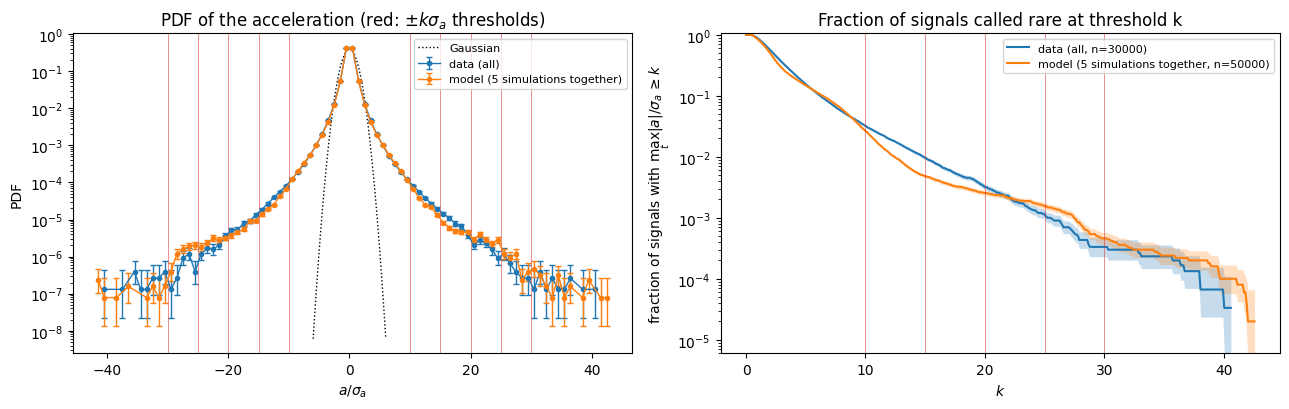

,data: rare signals,data: fraction,data: points above,data: points per rare signal,model: rare signals (all seeds),model: fraction (all seeds),model: points above,model: points per rare signal,"model: fraction, std across seeds"
threshold (sigma_a),,,,,,,,,
10,960,0.032,4237,4.41,1325,0.0265,5558,4.19,0.000806
15,289,0.00963,862,2.98,242,0.00484,1303,5.38,0.000152
20,96,0.0032,221,2.3,127,0.00254,533,4.2,0.000261
25,33,0.0011,70,2.12,79,0.00158,179,2.27,0.000268
30,10,0.000333,27,2.7,23,0.00046,39,1.7,8.94e-05


In [13]:
def compute_acceleration(X):
    '''a(t) = X(t+1) - X(t), lag-1 increment (the last-to-first wrap-around is NOT included).'''
    return X[..., 1:] - X[..., :-1]

SIGMA_A = compute_acceleration(x1).flatten().std().item()   # reference: x1, every point

def extremeness_sigma(X):
    '''(n,) peak acceleration of each signal in units of SIGMA_A: e = max_t |a(t)| / SIGMA_A.'''
    a = compute_acceleration(X)
    return (a.abs().amax(dim=tuple(range(1, a.ndim))) / SIGMA_A).cpu().numpy()

def split_by_sigma(e_sig, k):
    '''(idx_typical, idx_rare): rare = peak acceleration >= k sigma_a.'''
    is_rare = e_sig >= k
    return np.flatnonzero(~is_rare).tolist(), np.flatnonzero(is_rare).tolist()

from scipy import stats

def poisson_interval(n, cl=0.6827):
    '''Exact (Garwood) 68% interval on a Poisson count n. Lower edge > 0 for n >= 1, so it shows on a log axis.'''
    n = np.asarray(n, float)
    a = (1 - cl) / 2
    lo = np.where(n > 0, stats.chi2.ppf(a, 2 * np.maximum(n, 1)) / 2, 0.0)
    hi = stats.chi2.ppf(1 - a, 2 * n + 2) / 2
    return lo, hi

thresholds = sorted({*SIGMA_THRESHOLDS, SIGMA_RARE})
a_data = (compute_acceleration(x_eval) / SIGMA_A).flatten().cpu().numpy()
a_model_by_seed = {k: (compute_acceleration(x) / SIGMA_A).flatten().numpy() for k, x in x_model_by_seed.items()}
a_model = np.concatenate(list(a_model_by_seed.values()))
e_data = extremeness_sigma(x_eval)
e_model_by_seed = {k: extremeness_sigma(x) for k, x in x_model_by_seed.items()}
e_model = np.concatenate(list(e_model_by_seed.values()))

flat = lambda a: np.mean(a ** 4) / np.mean(a ** 2) ** 2
print(f"SIGMA_A (x1, every point) = {SIGMA_A:.4g} in x1 units")
print(f"data ({SPLIT_ON}): std(a)/SIGMA_A = {a_data.std():.4g}, flatness <a^4>/<a^2>^2 = {flat(a_data):.3g}, "
      f"max |a|/SIGMA_A = {np.abs(a_data).max():.3g}")
print(f"model ({len(a_model_by_seed)} simulations together): std(a)/SIGMA_A = {a_model.std():.4g}, "
      f"flatness = {flat(a_model):.3g}, max |a|/SIGMA_A = {np.abs(a_model).max():.3g}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
A = np.ceil(max(np.abs(a_data).max(), np.abs(a_model).max())) + 1
edges = np.linspace(-A, A, 2 * int(A) + 1)                     # 1-sigma-wide bins
ctr, bw = 0.5 * (edges[1:] + edges[:-1]), edges[1] - edges[0]
ctr, bw = 0.5 * (edges[1:] + edges[:-1]), edges[1] - edges[0]
for vals, c, lab in ((a_data, 'tab:blue', f'data ({SPLIT_ON})'),
                     (a_model, 'tab:orange', f'model ({len(x_model_by_seed)} simulations together)')):
    cnt, _ = np.histogram(vals, bins=edges)
    norm = len(vals) * bw
    lo, hi = poisson_interval(cnt)
    m = cnt > 0
    ax.errorbar(ctr[m], cnt[m] / norm, yerr=[(cnt - lo)[m] / norm, (hi - cnt)[m] / norm],
                fmt='o-', ms=3, lw=1, capsize=2, color=c, label=lab)
g = np.linspace(-6, 6, 300)
ax.plot(g, np.exp(-g ** 2 / 2) / np.sqrt(2 * np.pi), 'k:', lw=1, label='Gaussian')
for k in thresholds:
    ax.axvline(k, color='tab:red', lw=0.6, alpha=0.6); ax.axvline(-k, color='tab:red', lw=0.6, alpha=0.6)
ax.set_yscale('log'); ax.set_xlabel(r'$a/\sigma_a$'); ax.set_ylabel('PDF')
ax.set_title(r'PDF of the acceleration (red: $\pm k\sigma_a$ thresholds)'); ax.legend(fontsize=8)

ax = axes[1]
kk = np.linspace(0, A, 400)
for e, c, lab in ((e_data, 'tab:blue', f'data ({SPLIT_ON}, n={len(e_data)})'),
                  (e_model, 'tab:orange', f'model ({len(x_model_by_seed)} simulations together, n={len(e_model)})')):
    n_above = np.array([(e >= k).sum() for k in kk])       # number of signals with peak >= k
    m = n_above > 0                                        # stop where no signal is left
    lo, hi = poisson_interval(n_above)
    ax.plot(kk[m], n_above[m] / len(e), color=c, label=lab)
    ax.fill_between(kk[m], lo[m] / len(e), hi[m] / len(e), color=c, alpha=0.25, lw=0)
ax.set_ylim(bottom=0.3 / max(len(e_data), len(e_model)))
for k in thresholds:
    ax.axvline(k, color='tab:red', lw=0.6, alpha=0.6)
ax.set_yscale('log'); ax.set_xlabel(r'$k$'); ax.set_ylabel(r'fraction of signals with $\max_t|a|/\sigma_a \geq k$')
ax.set_title('Fraction of signals called rare at threshold k'); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

rows = []
for k in thresholds:
    per_seed = np.array([(e >= k).mean() for e in e_model_by_seed.values()])
    rows.append({'threshold (sigma_a)': k,
                 'data: rare signals': int((e_data >= k).sum()), 'data: fraction': (e_data >= k).mean(),
                 'data: points above': int((np.abs(a_data) >= k).sum()),
                 'data: points per rare signal': (np.abs(a_data) >= k).sum() / max((e_data >= k).sum(), 1),
                 'model: rare signals (all seeds)': int((e_model >= k).sum()), 'model: fraction (all seeds)': (e_model >= k).mean(),
                 'model: points above': int((np.abs(a_model) >= k).sum()),
                 'model: points per rare signal': (np.abs(a_model) >= k).sum() / max((e_model >= k).sum(), 1),
                 'model: fraction, std across seeds': per_seed.std(ddof=1) if len(per_seed) > 1 else np.nan})
display(pd.DataFrame(rows).set_index('threshold (sigma_a)'))

## σ split, and examples of each category

A signal of `x_eval` is **rare** if $e = \max_t |a(t)|/\sigma_a \ge$ `SIGMA_RARE`, and typical otherwise. One jump that big anywhere in the signal is enough. Below: the distribution of $e$ with the threshold, then examples. The red segment marks the biggest jump.

split on 'all' (n=30000) at 20σ: typical 29904, rare 96 (0.320%; 33 in x1, 63 held out)


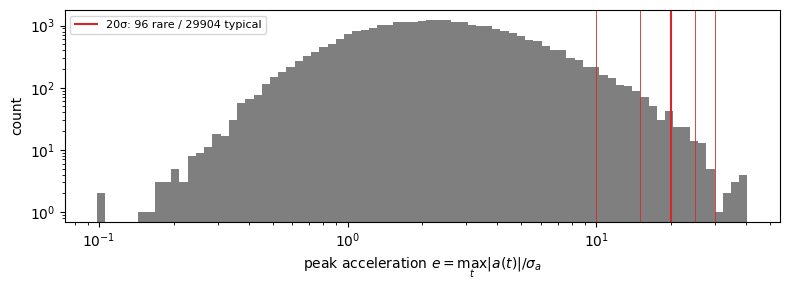

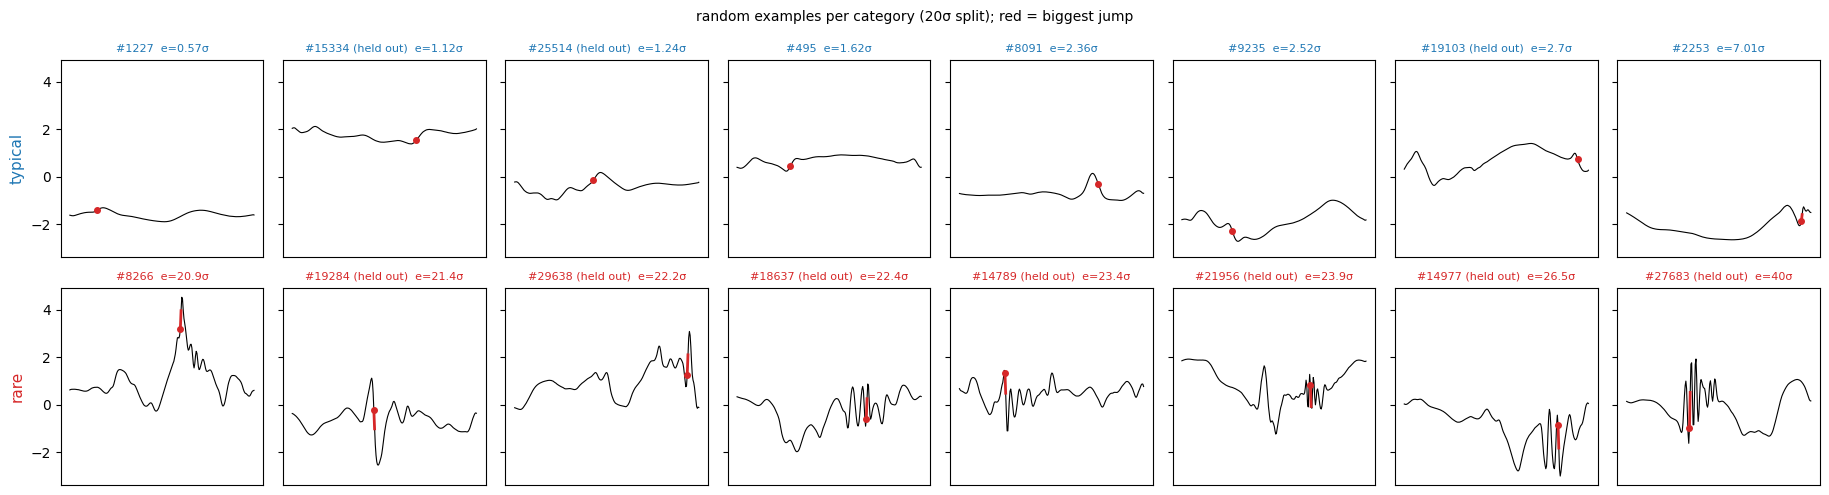

In [14]:
e_split = e_data                                           # (n_eval,) peak acceleration in sigma_a units
idx_typical, idx_rare = split_by_sigma(e_split, SIGMA_RARE)
category_indices = {'typical': idx_typical, 'rare': idx_rare}
category_colors = {'typical': 'tab:blue', 'rare': 'tab:red'}
rare_set = set(idx_rare)
P_LABEL = f'{SIGMA_RARE:g}σ'
n_heldout_rare = sum(i >= n1 for i in idx_rare)
print(f"split on {SPLIT_ON!r} (n={n_eval}) at {P_LABEL}: typical {len(idx_typical)}, rare {len(idx_rare)} "
      f"({100 * len(idx_rare) / n_eval:.3f}%; {len(idx_rare) - n_heldout_rare} in x1, {n_heldout_rare} held out)")
assert len(idx_rare) >= 2, f'fewer than 2 rare signals at {P_LABEL}: lower SIGMA_RARE or use SPLIT_ON="all"'
if len(idx_rare) < 30:
    print(f"WARNING: only {len(idx_rare)} rare signals -- every rare-set mean below has a large error bar "
          "(look at the bootstrap SE)")

t_jump = compute_acceleration(x_eval).abs()[:, 0].argmax(dim=-1).cpu().numpy()   # where the biggest jump is

fig, ax = plt.subplots(figsize=(8, 3))
bins = np.logspace(np.log10(e_split.min()), np.log10(e_split.max()), 80)
ax.hist(e_split, bins=bins, color='tab:gray')
for k in thresholds:
    ax.axvline(k, color=category_colors['rare'], lw=1.5 if k == SIGMA_RARE else 0.6,
               label=f'{P_LABEL}: {len(idx_rare)} rare / {len(idx_typical)} typical' if k == SIGMA_RARE else None)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'peak acceleration $e = \max_t |a(t)|/\sigma_a$'); ax.set_ylabel('count')
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

rng_ev = np.random.default_rng(EVENT_SEED)
picks = {}
for cat, idx in category_indices.items():
    idx = np.asarray(idx)
    k = min(N_EVENT_EXAMPLES, len(idx))
    if EVENT_PICK == 'extreme':
        order = np.argsort(e_split[idx])
        chosen = idx[order[::-1][:k]] if cat == 'rare' else idx[order[:k]]
    else:
        chosen = rng_ev.choice(idx, size=k, replace=False)
    picks[cat] = chosen[np.argsort(e_split[chosen])]

n_col = max(len(v) for v in picks.values())
fig, axes = plt.subplots(2, n_col, figsize=(2.3 * n_col, 5), sharey=True, squeeze=False)
for r, cat in enumerate(['typical', 'rare']):
    for c in range(n_col):
        ax = axes[r][c]
        if c >= len(picks[cat]):
            ax.axis('off'); continue
        i = picks[cat][c]
        sig = x_eval[i, 0].cpu().numpy()
        ax.plot(sig, lw=0.8, color='black')
        tj = t_jump[i]
        ax.plot([tj, tj + 1], sig[[tj, tj + 1]], color='tab:red', lw=2)
        ax.plot(tj, sig[tj], 'o', color='tab:red', ms=4)
        ax.set_title(f"#{i}{' (held out)' if i >= n1 else ''}  e={e_split[i]:.3g}σ", fontsize=8,
                     color=category_colors[cat])
        ax.set_xticks([])
    axes[r][0].set_ylabel(cat, color=category_colors[cat], fontsize=11)
fig.suptitle(f"{EVENT_PICK} examples per category ({P_LABEL} split); red = biggest jump", fontsize=10)
fig.tight_layout(); plt.show()

## Per-family log p contribution, split by category

Same $\theta^\top\varphi(x)$ as the original notebook, evaluated on `x_eval` and grouped by the σ split.

**Sign convention** (checked in `sde_routines.py`: the sampler ascends $+\nabla_x\,\theta^\top\varphi$): $p_\theta(x)\propto\exp(+\theta^\top\varphi(x))$, so $\theta^\top\varphi(x)=\log p_\theta(x)+\log Z(\theta)$.
Every "log p contribution" below is $\theta_F^\top\varphi_F(x)$ in this convention: higher means more likely.

In [15]:
phi_X = compute_phi_X(potentials_ref, x_eval).detach().cpu().double().numpy()   # (n_eval, n_features)
assert phi_X.shape == (n_eval, n_features), phi_X.shape
phi_by_seed = {k: phi_X if (PHI_SHARED or k == REFERENCE_SEED)
               else compute_phi_X(potentials_by_seed[k], x_eval).detach().cpu().double().numpy()
               for k in seed_keys}

ranges_with_total = {**family_ranges, 'TOTAL': (0, n_features)}
# C[F]: (n_seeds, n_eval) -- per-seed, per-signal log p contribution (nats) of family F
C = {F: np.stack([phi_by_seed[k][:, a:b] @ reg_all_np[s, a:b] for s, k in enumerate(seed_keys)])
     for F, (a, b) in ranges_with_total.items()}
# Seed-averaged contribution; with a shared phi_X this is exactly theta_reg_mean . phi(x)
C_bar = {F: C[F].mean(0) for F in C}
family_energy = {F: C_bar[F] for F in family_ranges}
total_log_p_unnorm = C_bar['TOTAL']

comparison = []
for category, idx in category_indices.items():
    for name in ranges_with_total:
        sample_totals = C_bar[name][idx]
        comparison.append({
            'category': category, 'family': name,
            'mean_total': sample_totals.mean(), 'std_total': sample_totals.std(ddof=1),
        })
comparison_df = pd.DataFrame(comparison)
print('seed-averaged theta; std_total = spread across signals')
display(comparison_df.pivot(index='family', columns='category', values=['mean_total', 'std_total']))

seed-averaged theta; std_total = spread across signals


mean_total         std_total        
category                                   rare typical      rare typical
family                                                                   
L_2_lowpass                              -0.714   -0.67     0.934   0.968
L_6                                        -104 -0.0899       249   0.876
Scalar_morlet_gaussianK                    -197    -102      40.5    33.6
Scalar_psi_gaussianK                       -557    -291       102    99.8
Scattering_Fourth_Order_Mod2_Imag_Q1       4.25 0.00674      15.9   0.321
Scattering_Fourth_Order_Mod2_Real_Q1        155   0.457       244    3.33
TOTAL                                      -699    -394       129     131

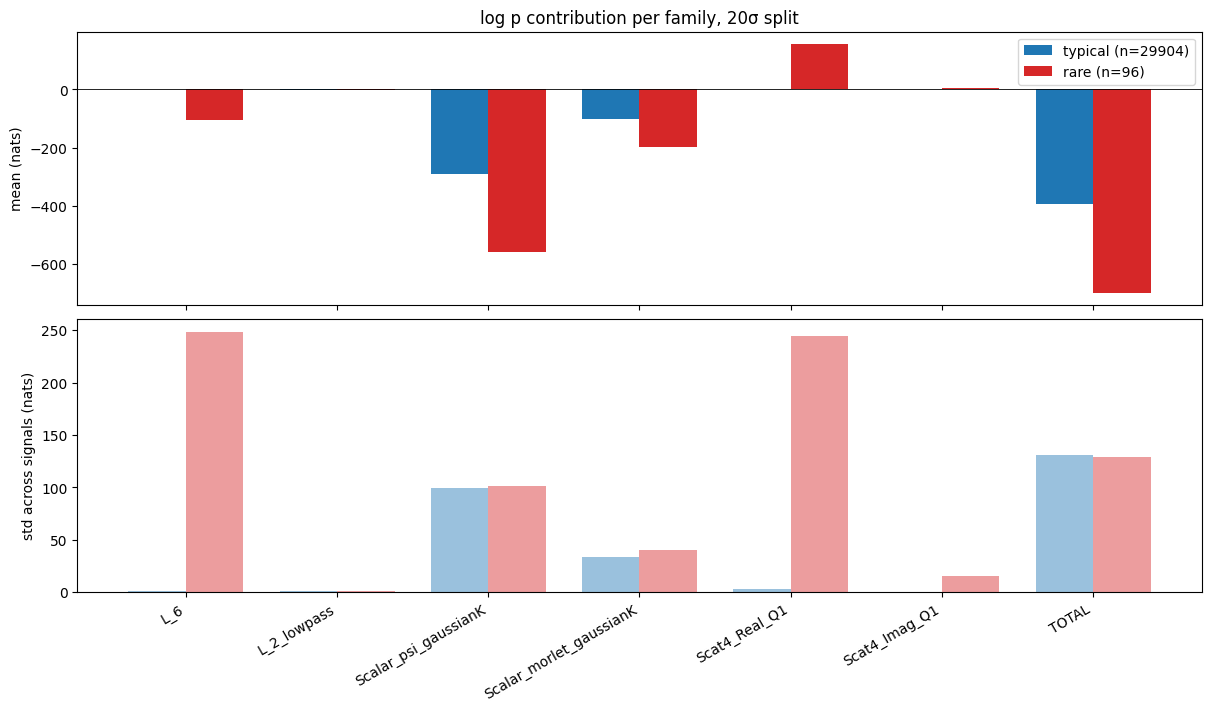

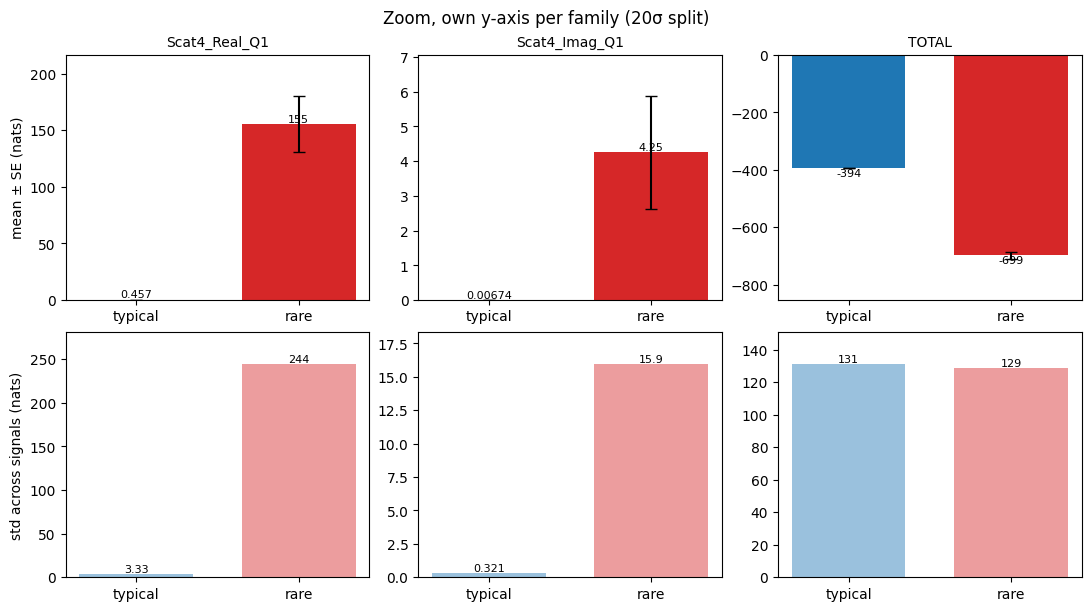

In [16]:
from matplotlib.colors import to_rgba

short = lambda F: F.replace('Scattering_Fourth_Order_Mod2_', 'Scat4_')
categories = list(category_indices.keys())
family_names = list(ranges_with_total.keys())   # all families + TOTAL
cat_stats = comparison_df.set_index(['category', 'family'])   # not called `stats`: that name is scipy.stats below
means = {c: cat_stats.loc[c].loc[family_names, 'mean_total'].to_numpy() for c in categories}
stds = {c: cat_stats.loc[c].loc[family_names, 'std_total'].to_numpy() for c in categories}
n_cat = {c: len(category_indices[c]) for c in categories}
width = 0.38
offsets = {c: (i - (len(categories) - 1) / 2) * width for i, c in enumerate(categories)}

# Full range: all families on one axis (the L_6 / Scalar families set the scale)
x = np.arange(len(family_names))
fig, (ax_mean, ax_std) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, constrained_layout=True)
for c in categories:
    ax_mean.bar(x + offsets[c], means[c], width, color=category_colors[c], label=f'{c} (n={n_cat[c]})')
    ax_std.bar(x + offsets[c], stds[c], width, color=to_rgba(category_colors[c], 0.45), label=c)
ax_mean.axhline(0, color='k', lw=0.6)
ax_mean.set_ylabel('mean (nats)'); ax_std.set_ylabel('std across signals (nats)')
ax_std.set_xticks(x); ax_std.set_xticklabels([short(F) for F in family_names], rotation=30, ha='right')
ax_mean.set_title(f'log p contribution per family, {P_LABEL} split'); ax_mean.legend()
plt.show()

# Zoom: one panel per family in ZOOM_FAMILIES, each with its OWN y-axis (otherwise Scat4_Real's
# scale flattens Scat4_Imag). Error bars on the mean = standard error (std / sqrt(n)).
fig, axes = plt.subplots(2, len(ZOOM_FAMILIES), figsize=(3.6 * len(ZOOM_FAMILIES), 6),
                         squeeze=False, constrained_layout=True)
for j, F in enumerate(ZOOM_FAMILIES):
    k = family_names.index(F)
    ax_m, ax_s = axes[0][j], axes[1][j]
    for i, c in enumerate(categories):
        m, s = means[c][k], stds[c][k]
        ax_m.bar(i, m, 0.7, yerr=s / np.sqrt(n_cat[c]), capsize=4, color=category_colors[c])
        ax_m.annotate(f'{m:.3g}', (i, m), ha='center', va='bottom' if m >= 0 else 'top', fontsize=8)
        ax_s.bar(i, s, 0.7, color=to_rgba(category_colors[c], 0.45))
        ax_s.annotate(f'{s:.3g}', (i, s), ha='center', va='bottom', fontsize=8)
    ax_m.axhline(0, color='k', lw=0.6)
    ax_m.margins(y=0.2); ax_s.margins(y=0.15)
    ax_m.set_title(short(F), fontsize=10)
    for ax in (ax_m, ax_s):
        ax.set_xticks(range(len(categories))); ax.set_xticklabels(categories)
axes[0][0].set_ylabel('mean ± SE (nats)'); axes[1][0].set_ylabel('std across signals (nats)')
fig.suptitle(f'Zoom, own y-axis per family ({P_LABEL} split)')
plt.show()

## log p, typical vs rare

$\theta^\top\varphi(x)$ = $\log p_\theta(x)$ up to $-\log Z(\theta)$, the same constant for both categories, so the gap between them is exact. With few rare signals, a histogram of the rare set says little. So each rare signal is drawn as a tick on top of the typical histogram, and the cell prints **where each rare signal ranks** in log p among all signals (percentile 0 = least likely signal of `x_eval`). The Mann–Whitney test asks whether rare signals have lower log p than typical ones, without assuming any shape for the distributions.

typical: best gumbel_l, loc=-331, scale=114.9
rare: best gumbel_l, loc=-637.4, scale=112.5


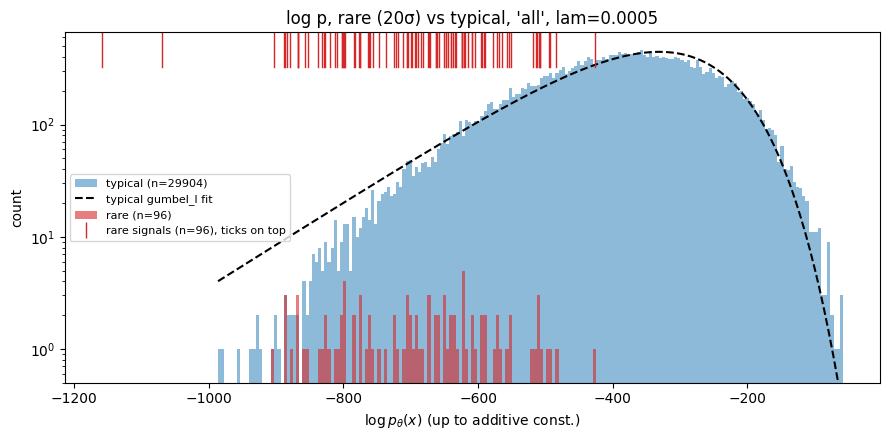

mean log p: rare = -698.5, typical = -393.7  -> rare < typical: True
Mann-Whitney (H1: rare has lower log p): U = 1.4e+05, p = 4.44e-53
log p percentile of the rare signals: median 2.48, fraction in the least likely 1%: 0.35


,held out,peak accel (sigma_a),log p,log p percentile
signal,,,,
4592,False,40.7,-879,0.08
27683,True,40,-1.16e+03,0.00333
18913,True,38,-867,0.103
19126,True,37.9,-634,4.82
4578,False,36.6,-887,0.06
...,...,...,...,...
8806,False,20.3,-513,18.1
2461,False,20.3,-698,2.16
28794,True,20.2,-640,4.44


within the rare set: Spearman(peak acceleration, log p) = -0.204  (< 0: the more extreme, the less likely)


In [17]:
from scipy import stats

logp_all = np.asarray(total_log_p_unnorm, dtype=float)
logp_by_category = {cat: logp_all[idx] for cat, idx in category_indices.items()}
logp_pct = stats.rankdata(logp_all) / len(logp_all) * 100     # log p percentile of every signal (0 = least likely)

# Gumbel fit only where there are enough signals for it to mean something
gumbel_fits = {}
for cat, x in logp_by_category.items():
    if len(x) < 50:
        print(f"{cat}: n={len(x)} < 50, no Gumbel fit")
        continue
    cands = {}
    for name, dist in (('gumbel_r', stats.gumbel_r), ('gumbel_l', stats.gumbel_l)):
        loc, scale = dist.fit(x)
        cands[name] = dict(dist=dist, loc=loc, scale=scale, loglik=dist.logpdf(x, loc, scale).sum())
    best = max(cands, key=lambda k: cands[k]['loglik'])
    gumbel_fits[cat] = {**cands[best], 'kind': best}
    print(f"{cat}: best {best}, loc={cands[best]['loc']:.4g}, scale={cands[best]['scale']:.4g}")

fig, ax = plt.subplots(figsize=(9, 4.5))
_, edges, _ = ax.hist(logp_by_category['typical'], bins=200, color=category_colors['typical'], alpha=0.5,
                      label=f"typical (n={len(idx_typical)})")
if 'typical' in gumbel_fits:
    f = gumbel_fits['typical']; grid = np.linspace(edges[0], edges[-1], 400)
    ax.plot(grid, f['dist'].pdf(grid, f['loc'], f['scale']) * len(idx_typical) * (edges[1] - edges[0]),
            'k--', lw=1.5, label=f"typical {f['kind']} fit")
if len(idx_rare) >= 50:
    ax.hist(logp_by_category['rare'], bins=edges, color=category_colors['rare'], alpha=0.6, label=f'rare (n={len(idx_rare)})')
ymax = ax.get_ylim()[1]
for v in logp_by_category['rare']:
    ax.axvline(v, ymin=0.9, ymax=1.0, color=category_colors['rare'], lw=1)
ax.plot([], [], '|', color=category_colors['rare'], ms=12, label=f'rare signals (n={len(idx_rare)}), ticks on top')
ax.set_yscale('log'); ax.set_ylim(bottom=0.5)
ax.set_xlabel(r'$\log p_\theta(x)$ (up to additive const.)'); ax.set_ylabel('count')
ax.set_title(f'log p, rare ({P_LABEL}) vs typical, {SPLIT_ON!r}, {LAM_LABEL}'); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

mw = stats.mannwhitneyu(logp_by_category['rare'], logp_by_category['typical'], alternative='less')
print(f"mean log p: rare = {logp_by_category['rare'].mean():.4g}, typical = {logp_by_category['typical'].mean():.4g}  "
      f"-> rare < typical: {logp_by_category['rare'].mean() < logp_by_category['typical'].mean()}")
print(f"Mann-Whitney (H1: rare has lower log p): U = {mw.statistic:.4g}, p = {mw.pvalue:.3g}")
print(f"log p percentile of the rare signals: median {np.median(logp_pct[idx_rare]):.2f}, "
      f"fraction in the least likely 1%: {(logp_pct[idx_rare] <= 1).mean():.2f}")

rare_tbl = pd.DataFrame({'signal': idx_rare, 'held out': [i >= n1 for i in idx_rare],
                         'peak accel (sigma_a)': e_split[idx_rare], 'log p': logp_all[idx_rare],
                         'log p percentile': logp_pct[idx_rare]}).sort_values('peak accel (sigma_a)', ascending=False)
display(rare_tbl.set_index('signal'))
rho_e = stats.spearmanr(e_split[idx_rare], logp_all[idx_rare]).correlation
print(f"within the rare set: Spearman(peak acceleration, log p) = {rho_e:.3f}  (< 0: the more extreme, the less likely)")

## Florentin's plot

Data signals ordered by $\log p_\theta$ (up to the constant), from least to most likely. The $\log p$ distribution has heavy outlier tails, so examples spaced **linearly** in $\log p$ fall mostly in empty tail regions. There the nearest signal is the same one several times, which gave duplicates. The default (`EXAMPLE_SPACING = 'quantile'`) spaces them equally in **rank** instead: panel $k$ is the signal at the $k$-th quantile within `EXAMPLE_RANGE`, so every panel is a distinct signal. The strip on top shows where the chosen examples sit in the $\log p$ histogram. Titles are red for rare and blue for typical signals.

In [18]:
# --- Florentin's plot (signals ordered by log p) ---
N_EXAMPLES = 16                  # wraps at 8 per row
EXAMPLE_SPACING = 'linear'     # 'quantile': equally spaced in rank of log p (every panel a distinct signal,
                                 #   insensitive to outliers); 'linear': equally spaced in log p value
EXAMPLE_RANGE = (0.05, 99.95)      # percentiles of log p the examples are drawn from; (0, 100) = full range
EXAMPLE_SHAREY = True            # same y-axis for every panel

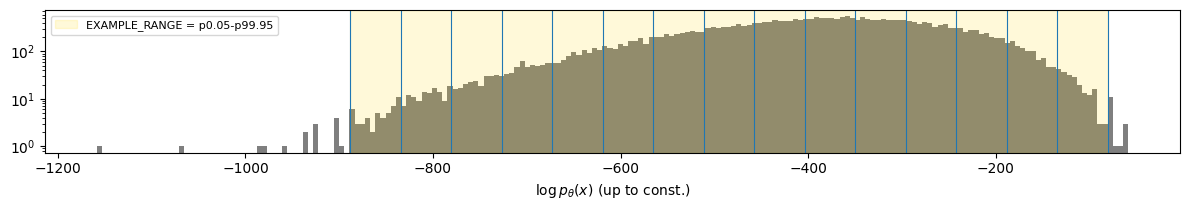

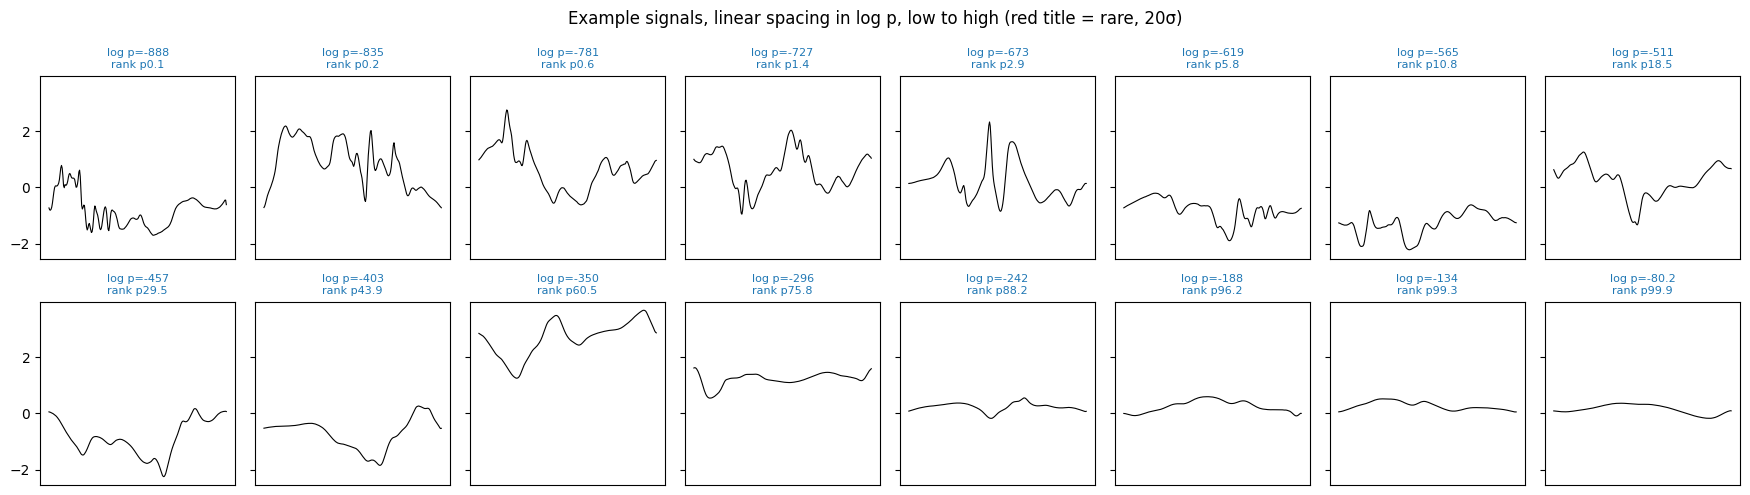

In [19]:
lo_q, hi_q = EXAMPLE_RANGE
order = np.argsort(logp_all)                                   # signal indices, low to high log p
rank_lo, rank_hi = (int(round(q / 100 * (n_eval - 1))) for q in (lo_q, hi_q))
if EXAMPLE_SPACING == 'quantile':
    ranks = np.unique(np.linspace(rank_lo, rank_hi, N_EXAMPLES).round().astype(int))
    example_idx = order[ranks]
elif EXAMPLE_SPACING == 'linear':
    targets = np.linspace(logp_all[order[rank_lo]], logp_all[order[rank_hi]], N_EXAMPLES)
    nearest = [int(np.argmin(np.abs(logp_all - t))) for t in targets]
    example_idx = np.array(list(dict.fromkeys(nearest)))      # drop repeats, keep order
    if len(example_idx) < N_EXAMPLES:
        print(f"linear spacing: {N_EXAMPLES - len(example_idx)} targets hit an already-shown signal, dropped")
else:
    raise ValueError(f"EXAMPLE_SPACING must be 'quantile' or 'linear', got {EXAMPLE_SPACING!r}")
rank_of = np.empty(n_eval, dtype=int); rank_of[order] = np.arange(n_eval)

# Where the examples sit in the log p distribution
fig, ax = plt.subplots(figsize=(12, 2.2))
ax.hist(logp_all, bins=200, color='tab:gray')
for i in example_idx:
    ax.axvline(logp_all[i], color=category_colors['rare' if i in rare_set else 'typical'], lw=0.8)
ax.axvspan(logp_all[order[rank_lo]], logp_all[order[rank_hi]], color='gold', alpha=0.15,
           label=f'EXAMPLE_RANGE = p{lo_q:g}-p{hi_q:g}')
ax.set_yscale('log'); ax.set_xlabel(r'$\log p_\theta(x)$ (up to const.)'); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

n_cols = 8
n_rows = math.ceil(len(example_idx) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.2 * n_cols, 2.5 * n_rows), sharey=EXAMPLE_SHAREY, squeeze=False)
for k, i in enumerate(example_idx):
    ax = axes[k // n_cols][k % n_cols]
    ax.plot(x_eval[i, 0].cpu().numpy(), lw=0.8, color='black')
    ax.set_title(f'log p={logp_all[i]:.3g}\nrank p{100 * rank_of[i] / (n_eval - 1):.1f}', fontsize=8,
                 color=category_colors['rare' if i in rare_set else 'typical'])
    ax.set_xticks([])
for j in range(len(example_idx), n_rows * n_cols):
    axes[j // n_cols][j % n_cols].axis('off')
fig.suptitle(f'Example signals, {EXAMPLE_SPACING} spacing in log p, low to high (red title = rare, {P_LABEL})')
fig.tight_layout(); plt.show()

## 1. Per-seed family contributions with error bars

For each seed $s$, `C[F][s, i]` $=\theta_{s,F}^\top\varphi_F(x_i)$ (log p contribution, nats), and `D[s, F]` = mean of `C[F][s]` over rare minus mean over typical. The table gives the mean/std of `D` across seeds, plus a bootstrap SE over the `len(idx_rare)` rare signals (resampled with the seed-averaged `C`; typical held fixed). The counts are printed below.

sum(family D) - TOTAL D = -1.023e-12  (should be ~0)
D over 5 seeds; bootstrap: 1000 resamples of the 96 rare signals (typical, n=29904, held fixed)


,family,mean_D,std_D_across_seeds,bootstrap_SE_rare
0,L_6,-103,61.5,24.7
1,L_2_lowpass,-0.0438,0.031,0.0939
2,Scalar_psi_gaussianK,-266,0.972,10.8
3,Scalar_morlet_gaussianK,-94.4,1.22,4.29
4,Scattering_Fourth_Order_Mod2_Real_Q1,155,61.4,24.5
5,Scattering_Fourth_Order_Mod2_Imag_Q1,4.24,4.47,1.62
6,TOTAL,-305,6.43,13.6


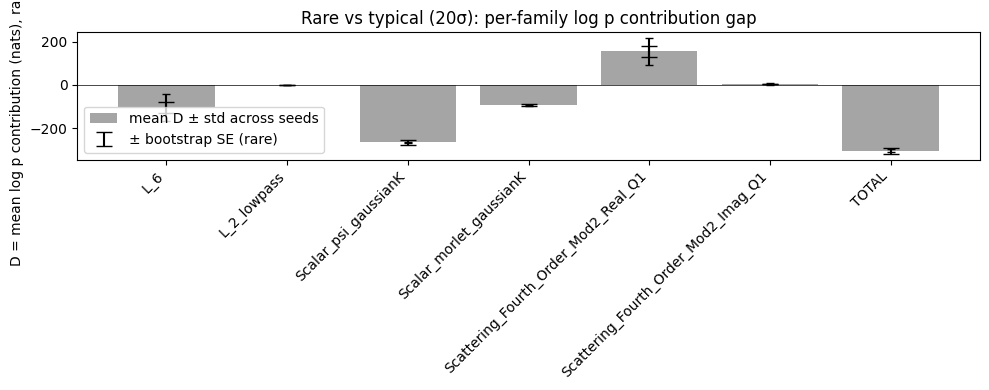

In [20]:
family_names_all = list(ranges_with_total.keys())  # all families + TOTAL
# C[F] (n_seeds, n1) and C_bar[F] (n1,) are built in the per-family energy cell above

D = np.stack([C[F][:, idx_rare].mean(axis=1) - C[F][:, idx_typical].mean(axis=1)
              for F in family_names_all], axis=1)  # (n_seeds, n_families+1)
D_mean = D.mean(axis=0)
D_std = D.std(axis=0, ddof=1) if n_seeds > 1 else np.full(D.shape[1], np.nan)

# sanity check: C[TOTAL] = sum_F C[F] exactly (linear), so D[TOTAL] should equal sum_F D[F]
total_i = family_names_all.index('TOTAL')
family_sum = sum(D_mean[i] for i, F in enumerate(family_names_all) if F != 'TOTAL')
print(f"sum(family D) - TOTAL D = {family_sum - D_mean[total_i]:.3e}  (should be ~0)")

# Bootstrap SE over the rare signals only (typical held fixed), using the
# seed-averaged C_bar.
rng = np.random.default_rng(BOOT_SEED)
n_boot = N_BOOT
idx_rare_arr = np.array(idx_rare)
typical_mean = {F: C_bar[F][idx_typical].mean() for F in family_names_all}
boot_D = np.empty((n_boot, len(family_names_all)))
for b in range(n_boot):
    resample = rng.choice(idx_rare_arr, size=len(idx_rare_arr), replace=True)
    boot_D[b] = [C_bar[F][resample].mean() - typical_mean[F] for F in family_names_all]
boot_se = boot_D.std(axis=0, ddof=1)
print(f"D over {n_seeds} seeds; bootstrap: {n_boot} resamples of the {len(idx_rare)} rare signals "
      f"(typical, n={len(idx_typical)}, held fixed)")

table1 = pd.DataFrame({'family': family_names_all, 'mean_D': D_mean,
                        'std_D_across_seeds': D_std, 'bootstrap_SE_rare': boot_se})
display(table1)

fig, ax = plt.subplots(figsize=(10, 4))
xpos = np.arange(len(family_names_all))
ax.bar(xpos, D_mean, yerr=D_std, capsize=3, color='tab:gray', alpha=0.7,
       label='mean D ± std across seeds')
ax.errorbar(xpos, D_mean, yerr=boot_se, fmt='none', ecolor='black', capsize=6, lw=1.5,
            label='± bootstrap SE (rare)')
ax.axhline(0, color='black', lw=0.5)
ax.set_xticks(xpos); ax.set_xticklabels(family_names_all, rotation=45, ha='right')
ax.set_ylabel('D = mean log p contribution (nats), rare - typical')
ax.set_title(f'Rare vs typical ({P_LABEL}): per-family log p contribution gap')
ax.legend()
fig.tight_layout()
plt.show()

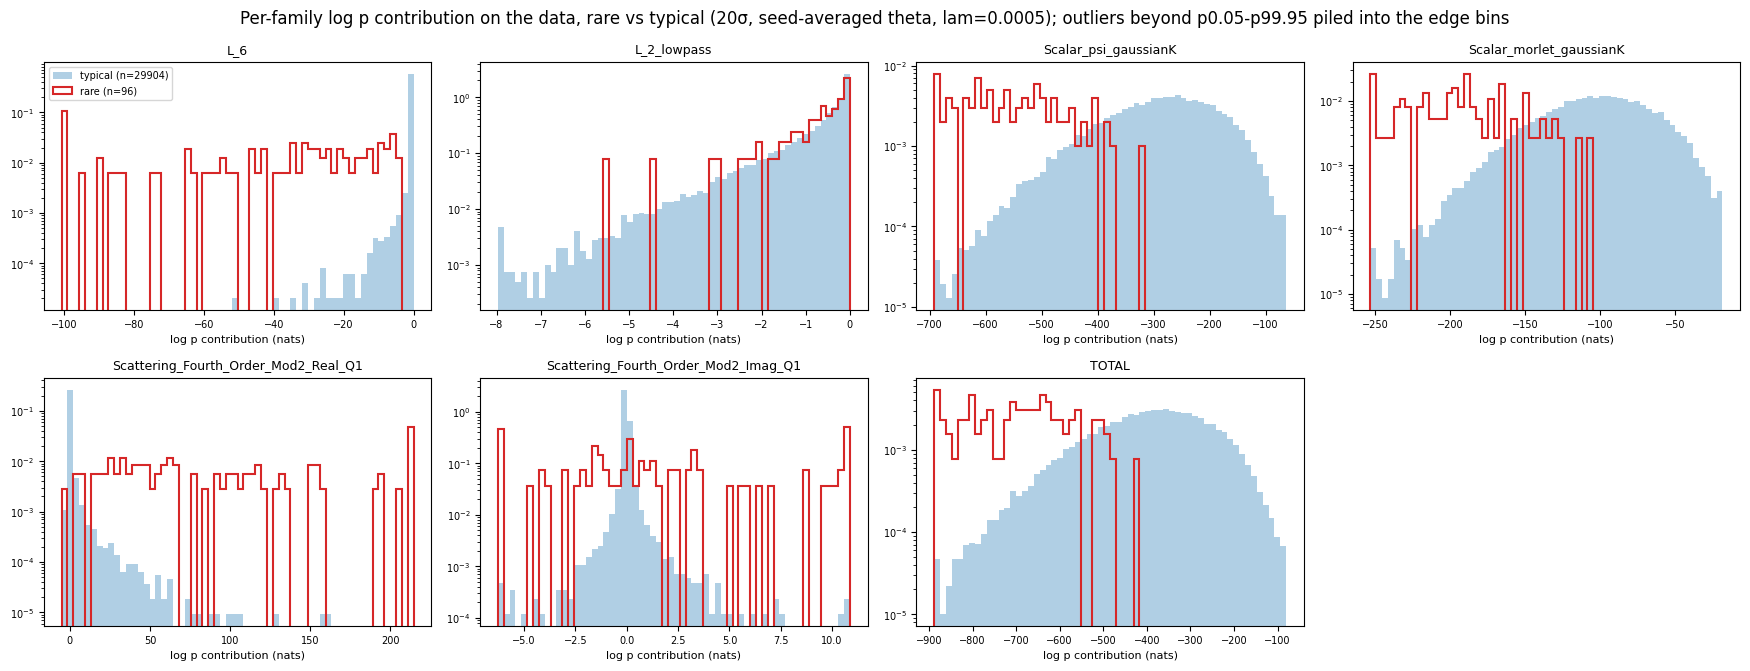

mean           std           skew  \
category                               rare typical  rare typical   rare   
family                                                                     
L_2_lowpass                          -0.714   -0.67 0.934   0.968   -2.6   
L_6                                    -104 -0.0899   249   0.876  -5.05   
Scalar_morlet_gaussianK                -197    -102  40.5    33.6 -0.386   
Scalar_psi_gaussianK                   -557    -291   102    99.8 -0.339   
Scattering_Fourth_Order_Mod2_Imag_Q1   4.25 0.00674  15.9   0.321   4.21   
Scattering_Fourth_Order_Mod2_Real_Q1    155   0.457   244    3.33   3.73   
TOTAL                                  -699    -394   129     131 -0.558   

                                             excess kurtosis           \
category                             typical            rare  typical   
family                                                                  
L_2_lowpass                            -2.83            8.51     12.2   
L_6                                      -26            28.5      940   
Scalar_morlet_gaussianK               -0.368           0.407    0.179   
Scalar_psi_gaussianK                  -0.537           0.333    0.214   
Scattering_Fourth_Order_Mod2_Imag_Q1    26.7              25 2.26e+03   
Scattering_Fourth_Order_Mod2_Real_Q1      21            15.3      660   
TOTAL                                 -0.473           0.814     0.12   

                                            p1               p99            
category                                  rare typical      rare   typical  
family                                                                      
L_2_lowpass                              -4.49   -4.53 -0.000852 -0.000251  
L_6                                  -1.27e+03   -1.56     -4.91 -4.19e-06  
Scalar_morlet_gaussianK                   -308    -189      -116       -35  
Scalar_psi_gaussianK                      -853    -561      -372      -105  
Scattering_Fourth_Order_Mod2_Imag_Q1     -14.8  -0.448      56.5     0.564  
Scattering_Fourth_Order_Mod2_Real_Q1      3.79  -0.688  1.27e+03      8.17  
TOTAL                                -1.07e+03    -742      -481      -144

In [21]:
# Shape of each family's log p contribution C_F(x) = theta_F . phi_F(x) on the data (x1),
# seed-averaged theta, rare vs typical overlaid. density=True: the two categories have very
# different sizes (n printed in the legend), so compare shapes, not counts. Each panel has its own x-range
# (the Scattering families are orders of magnitude smaller than L_6).
from scipy import stats

fams = list(ranges_with_total.keys())            # all families + TOTAL
n_cols = 4
n_rows = math.ceil(len(fams) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.4 * n_cols, 3.4 * n_rows), squeeze=False)

shape_rows = []
for i, F in enumerate(fams):
    ax = axes[i // n_cols][i % n_cols]
    vals = C_bar[F]
    lo, hi = np.percentile(vals, [0.05, 99.95])   # clip extreme outliers from the bin range only
    edges = np.linspace(lo, hi, 61)
    for cat, idx in category_indices.items():
        v = vals[idx]
        ax.hist(np.clip(v, lo, hi), bins=edges, density=True, histtype='stepfilled' if cat == 'typical' else 'step',
                color=category_colors[cat], alpha=0.35 if cat == 'typical' else 1.0, lw=1.5,
                label=f'{cat} (n={len(v)})')
        shape_rows.append({'family': F, 'category': cat, 'mean': v.mean(), 'std': v.std(ddof=1),
                           'skew': stats.skew(v), 'excess kurtosis': stats.kurtosis(v),
                           'p1': np.percentile(v, 1), 'p99': np.percentile(v, 99)})
    ax.set_yscale('log')
    ax.set_title(F, fontsize=9)
    ax.set_xlabel('log p contribution (nats)', fontsize=8)
    ax.tick_params(labelsize=7)
axes[0][0].legend(fontsize=7)
for j in range(len(fams), n_rows * n_cols):
    axes[j // n_cols][j % n_cols].axis('off')
fig.suptitle(f'Per-family log p contribution on the data, rare vs typical ({P_LABEL}, seed-averaged theta, {LAM_LABEL}); '
             'outliers beyond p0.05-p99.95 piled into the edge bins')
fig.tight_layout(); plt.show()

shape_df = pd.DataFrame(shape_rows).set_index(['family', 'category'])
display(shape_df.unstack('category'))

## 2. Robustness to the threshold

Seed-mean gap `D` (rare − typical) for each threshold in `SIGMA_THRESHOLDS`, with a bootstrap SE over the rare signals for TOTAL. Thresholds with fewer than 2 rare signals are skipped. Watch the number of rare signals: at 25–30σ there are only a handful.

In [22]:
table2, extra = {}, {}
rng = np.random.default_rng(BOOT_SEED)
for k in thresholds:
    idx_typ_k, idx_rare_k = split_by_sigma(e_split, k)
    if len(idx_rare_k) < 2:
        print(f"{k:g}σ: {len(idx_rare_k)} rare signal(s), skipped")
        continue
    col = f'{k:g}σ'
    table2[col] = [C[F][:, idx_rare_k].mean(axis=1).mean() - C[F][:, idx_typ_k].mean(axis=1).mean()
                   for F in family_names_all]
    tot = C_bar['TOTAL']; typ_mean = tot[idx_typ_k].mean(); r = np.asarray(idx_rare_k)
    boot = [tot[rng.choice(r, len(r))].mean() - typ_mean for _ in range(N_BOOT)]
    extra[col] = {'n_rare': len(idx_rare_k), 'TOTAL bootstrap SE': np.std(boot, ddof=1)}
table2_df = pd.DataFrame(table2, index=family_names_all)
display(pd.concat([table2_df, pd.DataFrame(extra)]))

,10σ,15σ,20σ,25σ,30σ
L_6,-12.5,-39.3,-103,-237,-585
L_2_lowpass,0.0351,0.0462,-0.0438,-0.19,0.00349
Scalar_psi_gaussianK,-193,-222,-266,-295,-332
Scalar_morlet_gaussianK,-67.3,-79.5,-94.4,-106,-110
Scattering_Fourth_Order_Mod2_Real_Q1,24.1,68.8,155,297,581
Scattering_Fourth_Order_Mod2_Imag_Q1,0.567,1.68,4.24,10.3,25.1
TOTAL,-248,-271,-305,-330,-421
n_rare,960,289,96,33,10
TOTAL bootstrap SE,3.74,7.18,12.9,26.3,65.2


## 3. Continuous version (no split)

Per family: centered log p contribution vs the peak acceleration $e$ (in σ_a, log x-axis), with the thresholds drawn and the rare signals highlighted. Table: Spearman rank correlation per family. This is the version that doesn't depend on where the threshold is put.

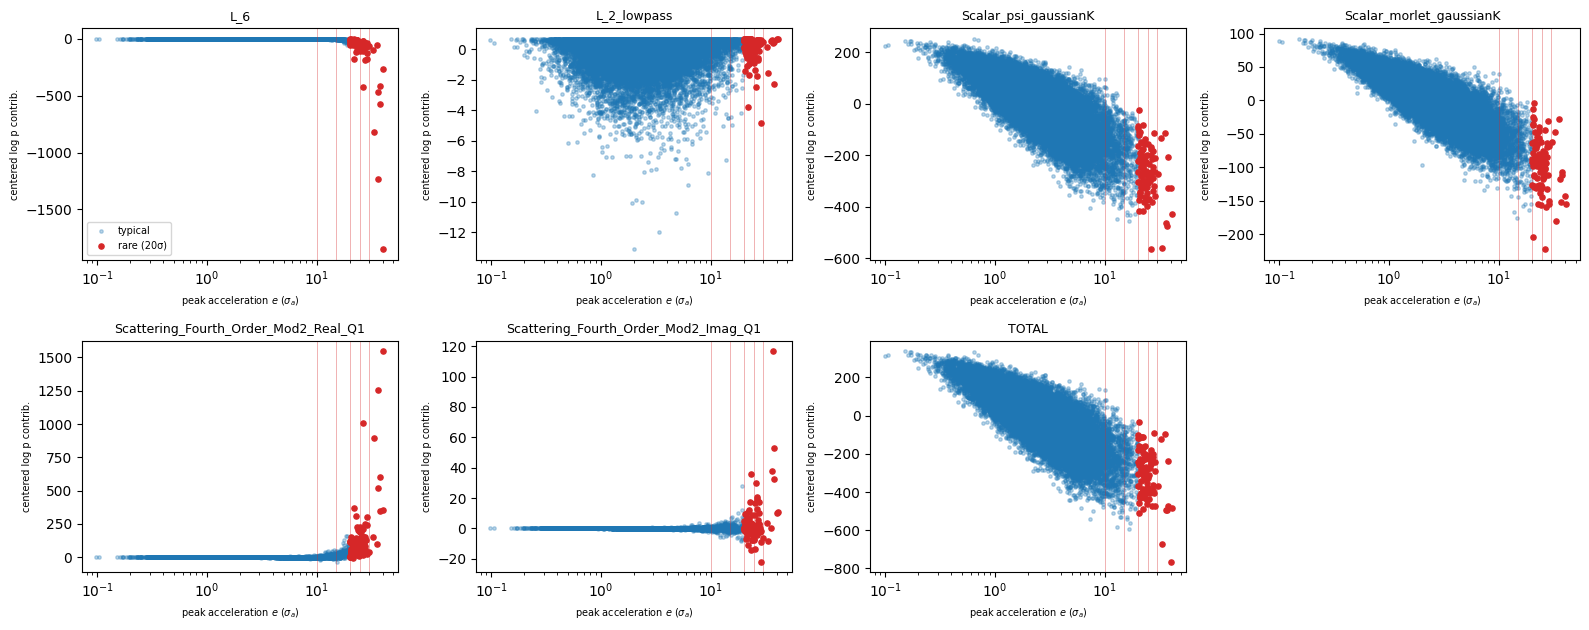

,family,spearman_rho
0,L_6,-0.69
1,L_2_lowpass,-0.0147
2,Scalar_psi_gaussianK,-0.773
3,Scalar_morlet_gaussianK,-0.811
4,Scattering_Fourth_Order_Mod2_Real_Q1,0.392
5,Scattering_Fourth_Order_Mod2_Imag_Q1,0.0181
6,TOTAL,-0.792


In [23]:
n_cols = 4
n_rows = math.ceil(len(family_names_all) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.2 * n_rows), squeeze=False)
mask_rare = np.zeros(n_eval, dtype=bool)
mask_rare[idx_rare] = True

spearman_rows = []
for i, F in enumerate(family_names_all):
    ax = axes[i // n_cols][i % n_cols]
    y = C_bar[F] - C_bar[F].mean()
    ax.scatter(e_split[~mask_rare], y[~mask_rare], s=6, alpha=0.3, color=category_colors['typical'], label='typical')
    ax.scatter(e_split[mask_rare], y[mask_rare], s=14, color=category_colors['rare'], label=f'rare ({P_LABEL})')
    for k in thresholds:
        ax.axvline(k, color='tab:red', lw=0.5, alpha=0.5)
    ax.set_xscale('log')
    ax.set_title(F, fontsize=9)
    ax.set_xlabel(r'peak acceleration $e$ ($\sigma_a$)', fontsize=7)
    ax.set_ylabel('centered log p contrib.', fontsize=7)
    spearman_rows.append({'family': F, 'spearman_rho': stats.spearmanr(e_split, C_bar[F]).correlation})
axes[0][0].legend(fontsize=7)
for j in range(len(family_names_all), n_rows * n_cols):
    axes[j // n_cols][j % n_cols].axis('off')
fig.tight_layout(); plt.show()

display(pd.DataFrame(spearman_rows))

## 4. Model samples: log p, and the model's own extreme events

Each seed's θ applied to that seed's samples, with φ from that seed's fitted potentials. 4a compares the TOTAL log p of data and model. 4b applies the **same σ threshold** to the model samples and compares the log p of the model's extreme events to the data's.

**Caveat.** With `THETA_SOURCE = 'theta_reg'` the MGD samples are not guaranteed to be samples of $p_{\Theta_{\rm reg}}$: $\Theta_{\rm reg}$ is a separate regularised fit (and depends on `LAM`). Read a gap between data and model log p with that in mind.

In [24]:
C_model = {}   # seed_key -> {family: (n_model,) array}, includes 'TOTAL'
for key, x_model in x_model_by_seed.items():
    phi_model = compute_phi_X(potentials_by_seed[key], x_model.to(device)).detach().cpu().double().numpy()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    s_idx = seed_keys.index(key)
    c_this = {F: phi_model[:, a:b] @ reg_all_np[s_idx, a:b] for F, (a, b) in family_ranges.items()}
    c_this['TOTAL'] = sum(c_this.values())
    C_model[key] = c_this
print(f"Computed model-sample log p contributions for {len(C_model)} seeds.")

Computed model-sample log p contributions for 5 seeds.


### 4a. Data vs model: TOTAL log p contribution and per-family std

L_6                                           data std=     17.57   model std=     11.48
L_2_lowpass                                   data std=     1.222   model std=     1.282
Scalar_psi_gaussianK                          data std=       101   model std=     85.28
Scalar_morlet_gaussianK                       data std=      34.2   model std=     29.92
Scattering_Fourth_Order_Mod2_Real_Q1          data std=     18.16   model std=     20.54
Scattering_Fourth_Order_Mod2_Imag_Q1          data std=     2.242   model std=     3.443


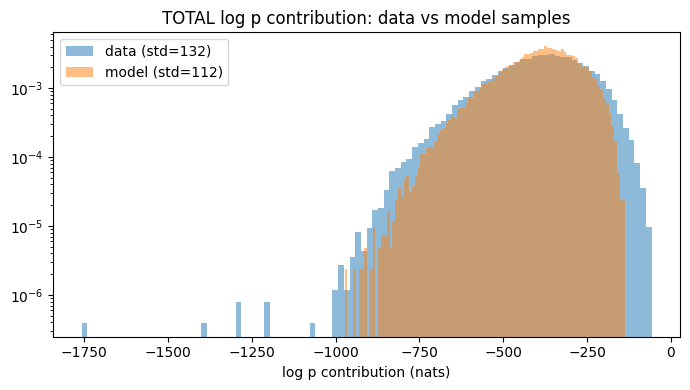

TOTAL mean: data = -394.7, model = -393.9 (each seed's own theta, pooled over 5 seeds)


In [25]:
model_keys = list(C_model.keys())
for F in family_names_all:
    data_vals = np.concatenate([C[F][seed_keys.index(k)] for k in model_keys])
    model_vals = np.concatenate([C_model[k][F] for k in model_keys])
    if F == 'TOTAL':
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.hist(data_vals, bins=100, density=True, alpha=0.5, color='tab:blue',
                label=f'data (std={data_vals.std():.3g})')
        ax.hist(model_vals, bins=100, density=True, alpha=0.5, color='tab:orange',
                label=f'model (std={model_vals.std():.3g})')
        ax.set_yscale('log'); ax.legend()
        ax.set_xlabel('log p contribution (nats)')
        ax.set_title('TOTAL log p contribution: data vs model samples')
        fig.tight_layout(); plt.show()
        print(f"TOTAL mean: data = {data_vals.mean():.4g}, model = {model_vals.mean():.4g} "
              f"(each seed's own theta, pooled over {len(model_keys)} seeds)")
    else:
        print(f"{F:45s} data std={data_vals.std():10.4g}   model std={model_vals.std():10.4g}")

### 4b. Extreme events of the model vs of the data, same σ threshold

In [ ]:
model_keys = list(C_model.keys())
rows = []
fig, ax = plt.subplots(figsize=(8, 4))
for key in model_keys:
    s = seed_keys.index(key)
    lp_data, lp_model = C['TOTAL'][s], C_model[key]['TOTAL']
    rare_m = e_model_by_seed[key] >= SIGMA_RARE
    rows.append({'seed': key,
                 'data: n rare': len(idx_rare), 'data: mean log p rare': lp_data[idx_rare].mean(),
                 'data: mean log p typical': lp_data[idx_typical].mean(),
                 'model: n rare': int(rare_m.sum()),
                 'model: mean log p rare': lp_model[rare_m].mean() if rare_m.any() else np.nan,
                 'model: mean log p typical': lp_model[~rare_m].mean()})
    ax.scatter(e_model_by_seed[key], lp_model, s=3, alpha=0.2, color='tab:orange',
               label='model samples (all seeds)' if s == 0 else None)
ax.scatter(e_split, C['TOTAL'][seed_keys.index(model_keys[0])], s=3, alpha=0.2, color='tab:blue',
           label=f'data ({SPLIT_ON}), {model_keys[0]} theta')
ax.axvline(SIGMA_RARE, color='tab:red', lw=1, label=P_LABEL)
ax.set_xscale('log'); ax.set_xlabel(r'peak acceleration $e$ ($\sigma_a$)'); ax.set_ylabel('TOTAL log p (up to const.)')
ax.set_title('log p vs peak acceleration: data vs model'); ax.legend(fontsize=8, markerscale=4)
fig.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index('seed'))